In [21]:
from anemone.experiment import *
import numpy as np
t0 = np.geomspace(1e-6, 1e-2, 31)
sq = Loop.square(40)
rx = Receiver()
t = np.array([-1.0526e-03, -9.2963e-04,  0.0000e+00,  2.5000e-06])
wv = np.array([0, 1, 1, 0])
waveform = Waveform(t, wv)
recfilter = FilterChain([
    ButterworthFilter(2.4e5, 1),
    ButterworthFilter(6.2e5, 1),
    ButterworthFilter(4.5e5, 2)
])

fwr0 = Forward(sq, rx, torch.from_numpy(t0))
fwr1 = Forward(sq, rx, torch.from_numpy(t0), tolerance=0.5e-5)
rho   = 10**(np.random.randn(6)+1)
thick = np.geomspace(2, 50, len(rho)-1)
sigma = torch.from_numpy(1./rho)
thick = torch.from_numpy(thick)
dbdt = fwr0(sigma, thick)

In [22]:
%%timeit
dbdt = fwr0(sigma, thick)

374 ms ± 33.3 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [23]:
%%timeit
dbdt = fwr1(sigma, thick)

148 ms ± 5.73 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [24]:
dbdt1 = fwr1(sigma, thick)
dbdt0 = fwr0(sigma, thick)

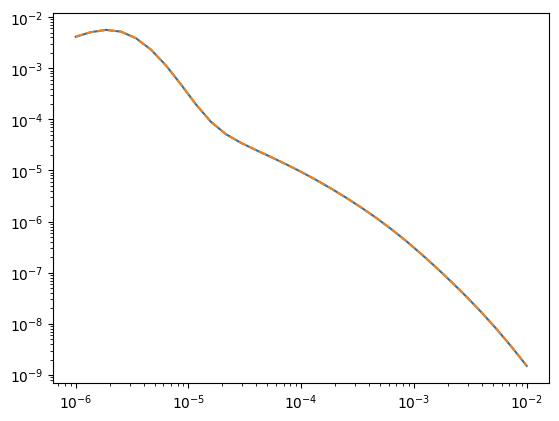

In [25]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.loglog(t0, dbdt0)
plt.loglog(t0, dbdt1, '--')